# Prediksi Harga Beras, Cabai Rawit, dan Bawang Merah di Provinsi DI Yogyakarta

Prediksi harga harian H+1, H+7, dan H+30 dengan alur: imputasi → transformasi `log1p` → *differencing* orde 1 → LightGBM (`ForecasterDirect`) dengan hyperparameter hasil Genetic Algorithm.

## 1. Import Library

Library data, visualisasi, ADF, LightGBM, XGBoost, dan PyGAD. Pipeline pemodelan (split, fitur, evaluasi, plot, EWS) diambil dari `research_common.py` yang dipakai bersama `code_run_training.ipynb`.

In [1]:
import warnings

import joblib as jl
import lightgbm as lgb
import matplotlib.pyplot as plt
import missingno as mgno
import numpy as np
import pandas as pd
import pygad
import seaborn as sns
import xgboost as xgb
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.model_selection import TimeSeriesSplit
from skforecast.exceptions import IgnoredArgumentWarning, LongTrainingWarning
from skforecast.model_selection import TimeSeriesFold, backtesting_forecaster
from statsmodels.tsa.stattools import adfuller

import research_common as rc

/home/yosiacokr/Documents/Project/pangan-forecasting/venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
warnings.simplefilter("ignore", category=IgnoredArgumentWarning)
warnings.simplefilter("ignore", category=LongTrainingWarning)

## 2. Memuat Dataset (CSV)

Baca `DATASET-BERAS.csv` ke `df_raw`.


In [3]:
df_raw = pd.read_csv("DATASET-BERAS.csv")
df_raw.head()

,tanggal,Beras Kualitas Bawah I,Beras Kualitas Bawah II,Beras Kualitas Medium I,Beras Kualitas Medium II,Beras Kualitas Super I,Beras Kualitas Super II,Bawang Merah Ukuran Sedang,Cabai Rawit Hijau,Cabai Rawit Merah
0,2021-01-04,10.4,9.9,11.75,11.0,12.75,12.4,32.25,56.25,62.50
1,2021-01-05,10.4,9.9,11.75,11.0,12.75,12.4,31.75,56.25,68.75
2,2021-01-06,10.4,9.9,11.75,11.0,12.75,12.4,31.75,56.25,68.75
3,2021-01-07,10.4,9.9,11.75,11.0,12.75,12.4,31.75,56.00,71.25
4,2021-01-08,10.4,9.9,11.75,11.0,12.75,12.4,31.75,56.00,71.25


## 3. Menetapkan Indeks Tanggal dan Split Train/Test

`rc.ResearchData.from_csv` mengubah kolom tanggal menjadi indeks harian, membagi data secara kronologis (fold terakhir `TimeSeriesSplit(n_splits=5)`), lalu mengimputasi: train dengan interpolasi berbasis waktu dan test dengan *forward fill* agar tidak memakai informasi masa depan. Langkah ini identik dengan `code_run_training.ipynb`.

In [4]:
R = rc.ResearchData.from_csv("DATASET-BERAS.csv")

Train: 2021-01-04 -> 2025-08-29
Test: 2025-08-30 -> 2026-08-03


In [5]:
# alias ringkas supaya sel EDA dan GA di bawah tetap mudah dibaca
df_raw, df_cleaned = R.df_raw, R.df_cleaned
raw_train, raw_test = R.raw_train, R.raw_test
commodity_cols, horizons = R.commodity_cols, R.horizons
data_by_col = R.data_by_col

## 4. Exploratory Data Analysis (EDA)

Ringkas kondisi data dan kelompokkan seluruh visualisasi setelah split serta preprocessing.


## 5. Memeriksa Informasi dan Tipe Data

Cek dimensi, tipe data, dan jumlah nilai non-null.


In [6]:
df_raw.info()
df_raw.dtypes

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 2038 entries, 2021-01-04 to 2026-08-03
Freq: D
Data columns (total 9 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Beras Kualitas Bawah I      1427 non-null   float64
 1   Beras Kualitas Bawah II     1427 non-null   float64
 2   Beras Kualitas Medium I     1427 non-null   float64
 3   Beras Kualitas Medium II    1427 non-null   float64
 4   Beras Kualitas Super I      1427 non-null   float64
 5   Beras Kualitas Super II     1427 non-null   float64
 6   Bawang Merah Ukuran Sedang  1427 non-null   float64
 7   Cabai Rawit Hijau           1427 non-null   float64
 8   Cabai Rawit Merah           1427 non-null   float64
dtypes: float64(9)
memory usage: 223.8 KB


Beras Kualitas Bawah I        float64
Beras Kualitas Bawah II       float64
Beras Kualitas Medium I       float64
Beras Kualitas Medium II      float64
Beras Kualitas Super I        float64
Beras Kualitas Super II       float64
Bawang Merah Ukuran Sedang    float64
Cabai Rawit Hijau             float64
Cabai Rawit Merah             float64
dtype: object

## 6. Persentase Missing Value

Hitung persentase nilai kosong pada setiap kolom.


In [7]:
percentages = (df_raw.isnull().sum() / len(df_raw)) * 100
print(percentages)

Beras Kualitas Bawah I        29.980373
Beras Kualitas Bawah II       29.980373
Beras Kualitas Medium I       29.980373
Beras Kualitas Medium II      29.980373
Beras Kualitas Super I        29.980373
Beras Kualitas Super II       29.980373
Bawang Merah Ukuran Sedang    29.980373
Cabai Rawit Hijau             29.980373
Cabai Rawit Merah             29.980373
dtype: float64


## 7. Visualisasi Distribusi dan Outlier

Boxplot memperlihatkan sebaran harga dan outlier tiap komoditas.


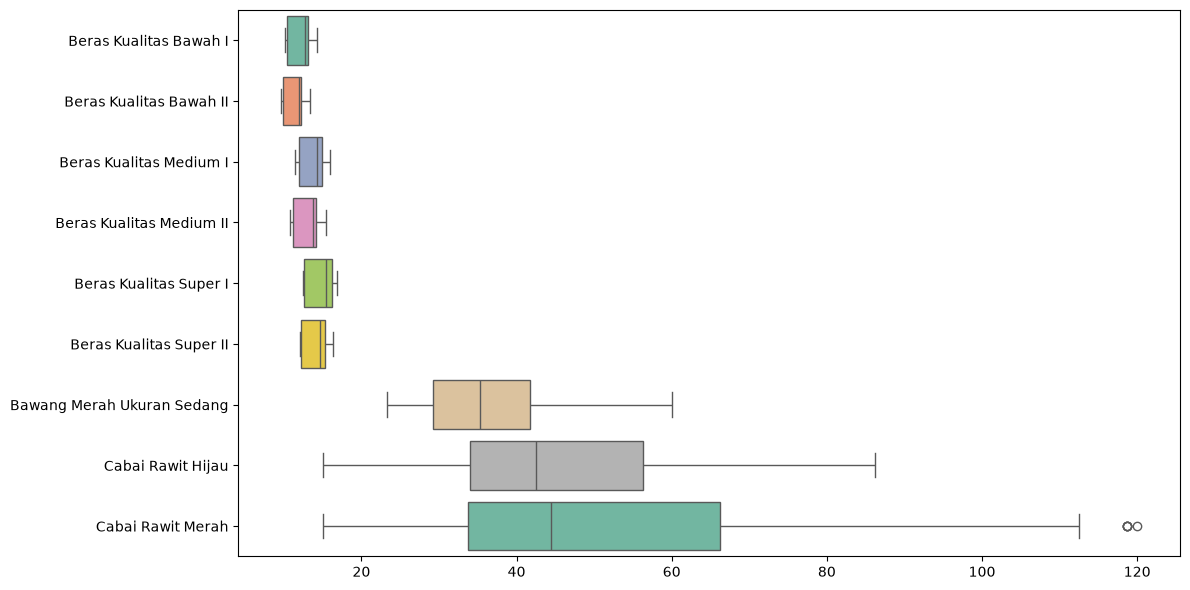

In [8]:
nums_cols = df_raw.select_dtypes(include="number").columns

plt.figure(figsize=(12, 6))
sns.boxplot(
    data=df_raw[nums_cols], orient="h", palette="Set2", showfliers=True, whis=1.5
)
plt.tight_layout()
plt.show()

## 8. Matriks Korelasi

Heatmap menampilkan korelasi antarharga komoditas.


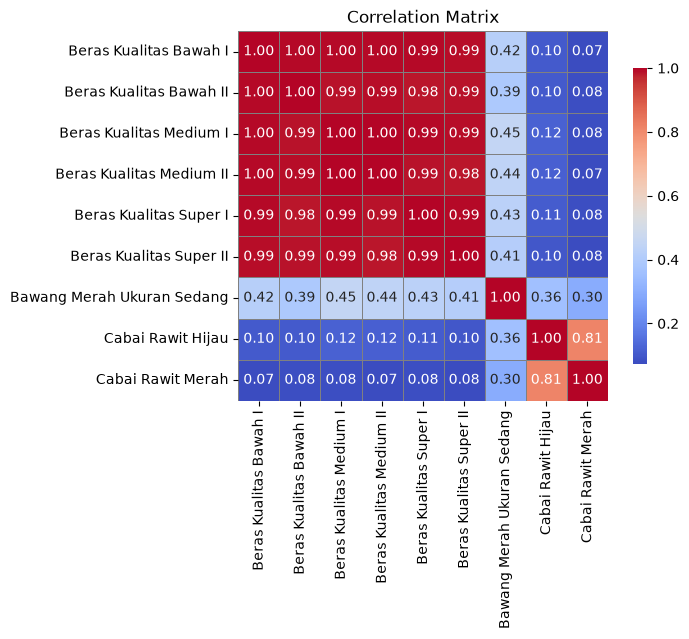

In [9]:
matrix_corr = df_raw[nums_cols].corr()
sns.heatmap(
    matrix_corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    square=True,
    cbar_kws={"shrink": 0.8},
    linewidths=0.5,
    linecolor="gray",
)
plt.title("Correlation Matrix")
plt.show()

## 9. Visualisasi Missing Value pada Data Asli

Bar chart menunjukkan jumlah dan persentase nilai kosong sebelum imputasi.


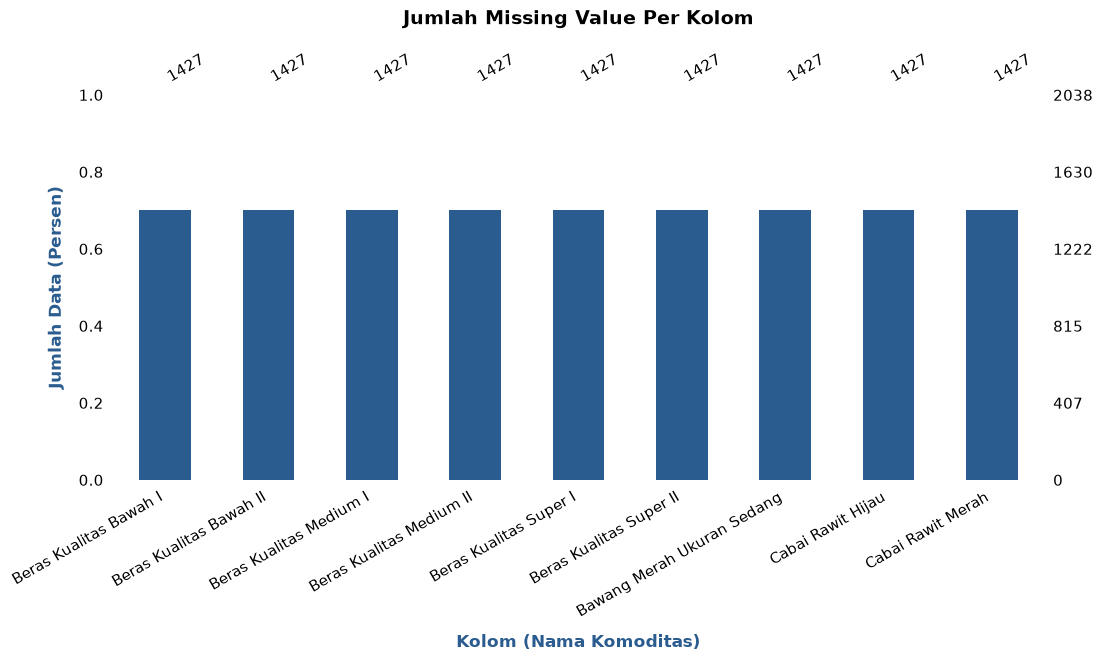

In [10]:
def plot_missing_bar(df, title):
    ax = mgno.bar(
        df,
        figsize=(12, 5),
        fontsize=11,
        labels=True,
        sort="ascending",
        p=True,
        color="#2b5c8f",
        label_rotation=30,
    )
    label_style = {
        "fontsize": 12,
        "labelpad": 10,
        "fontweight": "bold",
        "color": "#2b5c8f",
    }
    ax.set_title(title, fontsize=14, fontweight="bold", pad=20)
    ax.set_xlabel("Kolom (Nama Komoditas)", **label_style)
    ax.set_ylabel("Jumlah Data (Persen)", **label_style)


plot_missing_bar(df_raw, "Jumlah Missing Value Per Kolom")

## 10. Visualisasi Missing Value Setelah Imputasi

Grafik memastikan hasil imputasi train (interpolasi) dan test (*forward fill*) tidak menyisakan nilai kosong.

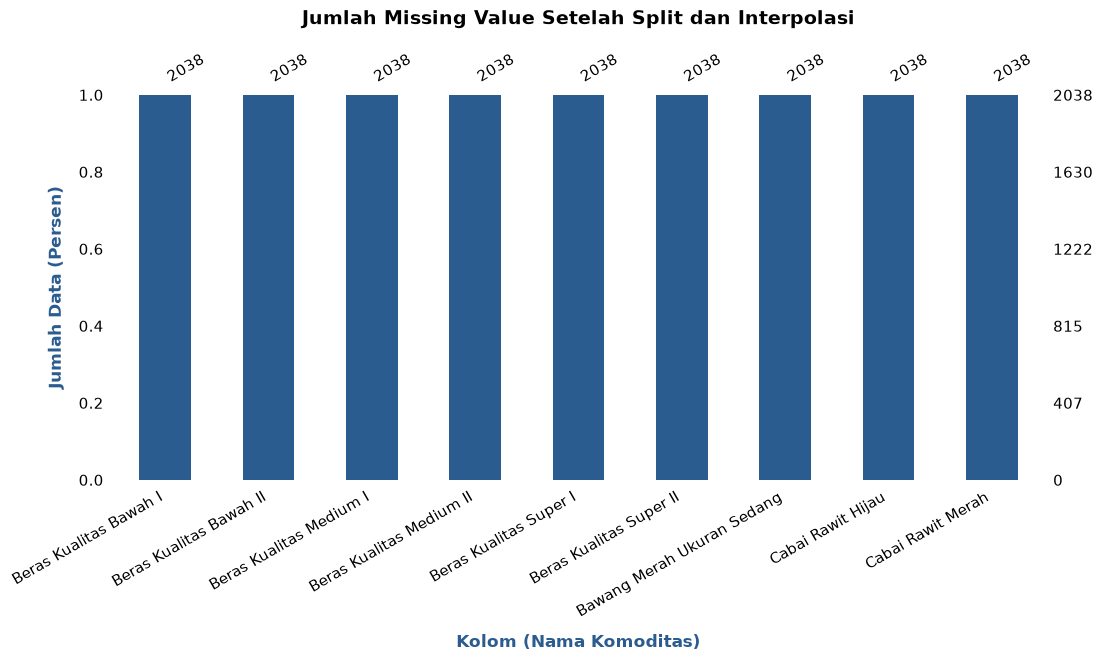

In [11]:
plot_missing_bar(df_cleaned, "Jumlah Missing Value Setelah Split dan Interpolasi")

## 11. Visualisasi Status Stasioneritas

Warna hijau menandai seri stasioner dan oranye menandai seri yang belum stasioner berdasarkan data train.


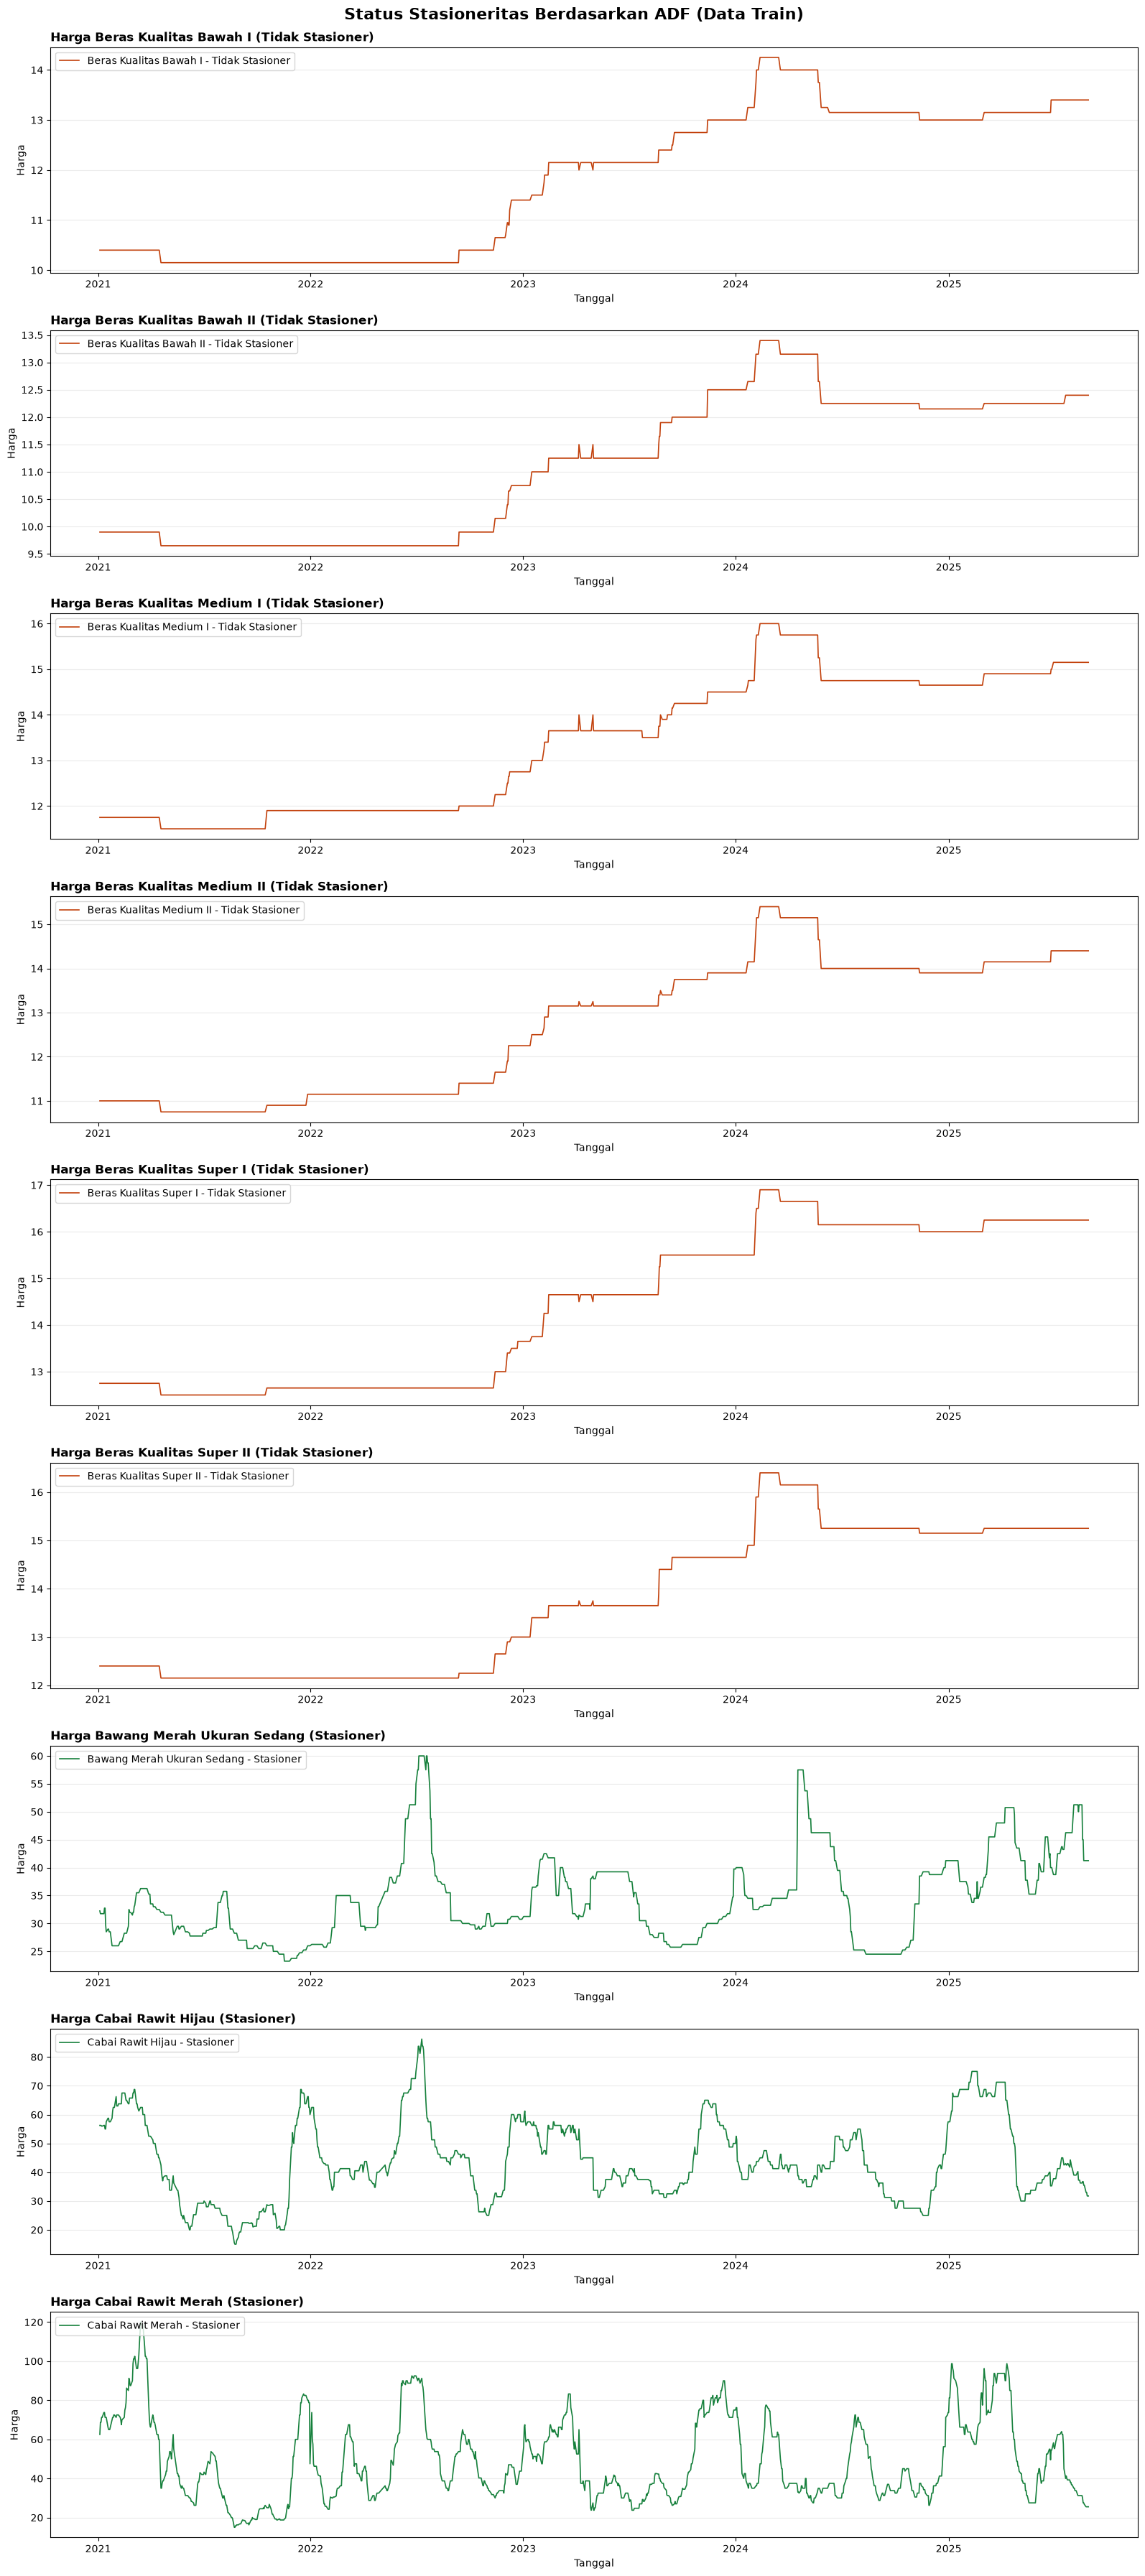

In [12]:
def adf_on_train(col):
    return adfuller(
        df_cleaned.loc[raw_train.index, col].dropna(),
        maxlag=None,
        regression="ct",
        autolag="AIC",
        store=False,
        regresults=False,
        result_object=False,
    )


adf_results = {col: adf_on_train(col) for col in df_cleaned.columns}
eda_stationarity_status = {
    col: "Stasioner" if result[1] < 0.05 else "Tidak Stasioner"
    for col, result in adf_results.items()
}

fig, axes = plt.subplots(
    nrows=len(adf_results),
    ncols=1,
    figsize=(16, 4 * len(adf_results)),
)

for ax, (col, status) in zip(axes, eda_stationarity_status.items()):
    color = "#16803c" if status == "Stasioner" else "#c2410c"
    ax.plot(
        raw_train.index,
        df_cleaned.loc[raw_train.index, col],
        color=color,
        linewidth=1.2,
        label=f"{col} - {status}",
    )
    ax.set_title(f"Harga {col} ({status})", loc="left", fontsize=12, fontweight="bold")
    ax.set_ylabel("Harga")
    ax.set_xlabel("Tanggal")
    ax.grid(axis="y", alpha=0.25)
    ax.legend(loc="upper left")

fig.suptitle(
    "Status Stasioneritas Berdasarkan ADF (Data Train)",
    fontsize=16,
    fontweight="bold",
    y=0.995,
)
fig.subplots_adjust(hspace=0.6, top=0.97)
plt.tight_layout()
plt.show()

## 12. Memverifikasi Hasil Imputasi Train dan Test

Pastikan hasil imputasi yang dibuat pada split awal memiliki index lengkap dan tidak menyisakan nilai kosong.


In [13]:
print(df_cleaned.isnull().sum())

Beras Kualitas Bawah I        0
Beras Kualitas Bawah II       0
Beras Kualitas Medium I       0
Beras Kualitas Medium II      0
Beras Kualitas Super I        0
Beras Kualitas Super II       0
Bawang Merah Ukuran Sedang    0
Cabai Rawit Hijau             0
Cabai Rawit Merah             0
dtype: int64


## 13. Memeriksa Persentase Missing Value Setelah Imputasi

Pastikan train dan test hasil imputasi tidak menyisakan nilai kosong.


In [14]:
feature_miss_value = df_cleaned.isnull().sum() * 100 / len(df_cleaned)
print(feature_miss_value)

Beras Kualitas Bawah I        0.0
Beras Kualitas Bawah II       0.0
Beras Kualitas Medium I       0.0
Beras Kualitas Medium II      0.0
Beras Kualitas Super I        0.0
Beras Kualitas Super II       0.0
Bawang Merah Ukuran Sedang    0.0
Cabai Rawit Hijau             0.0
Cabai Rawit Merah             0.0
dtype: float64


## 14. Uji Stasioneritas dengan ADF

Uji ADF mengevaluasi stasioneritas seri harga pada data train.

## 15. Menentukan Kolom Komoditas

Simpan nama kolom harga yang akan dianalisis.


In [15]:
commodity_cols

['Beras Kualitas Bawah I',
 'Beras Kualitas Bawah II',
 'Beras Kualitas Medium I',
 'Beras Kualitas Medium II',
 'Beras Kualitas Super I',
 'Beras Kualitas Super II',
 'Bawang Merah Ukuran Sedang',
 'Cabai Rawit Hijau',
 'Cabai Rawit Merah']

## 16. Menjalankan ADF dengan Tren dan Konstanta

Uji ADF menggunakan regresi `ct` pada data train untuk setiap komoditas.


In [16]:
for col in commodity_cols:
    result = adf_results[col]
    print(f"ADF Statistic for {col}: {result[0]}")
    print(f"p-value for {col}: {result[1]}")
    if len(result) > 4:
        print("Critical Values for: ")
        for key, value in result[4].items():
            print(f"\t{key}: {value}")
    status = "Stationary" if result[1] < 0.05 else "Non-Stationary"
    print(f"status : {status}")
    print("\n")

ADF Statistic for Beras Kualitas Bawah I: -1.6466364959197806
p-value for Beras Kualitas Bawah I: 0.7736418662615081
Critical Values for: 
	1%: -3.9641336654465316
	5%: -3.413089502928204
	10%: -3.128580413328423
status : Non-Stationary


ADF Statistic for Beras Kualitas Bawah II: -1.5019207602955766
p-value for Beras Kualitas Bawah II: 0.828473889714487
Critical Values for: 
	1%: -3.9641273173653064
	5%: -3.4130864282938935
	10%: -3.1285786037672016
status : Non-Stationary


ADF Statistic for Beras Kualitas Medium I: -2.0848275813746473
p-value for Beras Kualitas Medium I: 0.554581862991379
Critical Values for: 
	1%: -3.9641914824628577
	5%: -3.413117505850037
	10%: -3.128596894250325
status : Non-Stationary


ADF Statistic for Beras Kualitas Medium II: -1.7707217052073123
p-value for Beras Kualitas Medium II: 0.7187017904093482
Critical Values for: 
	1%: -3.9641336654465316
	5%: -3.413089502928204
	10%: -3.128580413328423
status : Non-Stationary


ADF Statistic for Beras Kualitas Sup

## 17. Transformasi Log

Seluruh komoditas memakai `log1p(harga)` sebagai target model untuk menstabilkan variansi; transformasi ini sudah dijalankan oleh `rc.ResearchData.from_csv`. Hasil ADF menjadi dasar *differencing* orde 1 pada tahap pemodelan: beras tidak stasioner, sedangkan bawang merah dan cabai rawit tetap di-*differencing* karena menurunkan galat prediksi.

In [17]:
df_cleaned_log = R.df_cleaned_log
log_to_price = rc.log_to_price
df_cleaned_log.head()

,Beras Kualitas Bawah I,Beras Kualitas Bawah II,Beras Kualitas Medium I,Beras Kualitas Medium II,Beras Kualitas Super I,Beras Kualitas Super II,Bawang Merah Ukuran Sedang,Cabai Rawit Hijau,Cabai Rawit Merah
tanggal,,,,,,,,,
2021-01-04,2.433613,2.388763,2.545531,2.484907,2.621039,2.595255,3.504055,4.047428,4.151040
2021-01-05,2.433613,2.388763,2.545531,2.484907,2.621039,2.595255,3.488903,4.047428,4.244917
2021-01-06,2.433613,2.388763,2.545531,2.484907,2.621039,2.595255,3.488903,4.047428,4.244917
2021-01-07,2.433613,2.388763,2.545531,2.484907,2.621039,2.595255,3.488903,4.043051,4.280132
2021-01-08,2.433613,2.388763,2.545531,2.484907,2.621039,2.595255,3.488903,4.043051,4.280132


In [18]:
for col in commodity_cols:
    print(
        f"{col}: ADF={eda_stationarity_status[col]} | "
        f"train {raw_train.index.min().date()} → {raw_train.index.max().date()} | "
        f"test {raw_test.index.min().date()} → {raw_test.index.max().date()}"
    )

Beras Kualitas Bawah I: ADF=Tidak Stasioner | train 2021-01-04 → 2025-08-29 | test 2025-08-30 → 2026-08-03
Beras Kualitas Bawah II: ADF=Tidak Stasioner | train 2021-01-04 → 2025-08-29 | test 2025-08-30 → 2026-08-03
Beras Kualitas Medium I: ADF=Tidak Stasioner | train 2021-01-04 → 2025-08-29 | test 2025-08-30 → 2026-08-03
Beras Kualitas Medium II: ADF=Tidak Stasioner | train 2021-01-04 → 2025-08-29 | test 2025-08-30 → 2026-08-03
Beras Kualitas Super I: ADF=Tidak Stasioner | train 2021-01-04 → 2025-08-29 | test 2025-08-30 → 2026-08-03
Beras Kualitas Super II: ADF=Tidak Stasioner | train 2021-01-04 → 2025-08-29 | test 2025-08-30 → 2026-08-03
Bawang Merah Ukuran Sedang: ADF=Stasioner | train 2021-01-04 → 2025-08-29 | test 2025-08-30 → 2026-08-03
Cabai Rawit Hijau: ADF=Stasioner | train 2021-01-04 → 2025-08-29 | test 2025-08-30 → 2026-08-03
Cabai Rawit Merah: ADF=Stasioner | train 2021-01-04 → 2025-08-29 | test 2025-08-30 → 2026-08-03


## 18. Feature Engineering

Fitur lag, rolling, dan kalender dibentuk otomatis oleh `ForecasterDirect` dari deret log harga.

## 19. Menyiapkan Fitur dan Forecaster

Konfigurasi berada di `research_common.py` sehingga sama persis dengan `code_run_training.ipynb`:

- Lag: 1, 7, dan 30 hari.
- Rolling: mean, std, min, dan max dengan jendela 7 dan 30 hari.
- Kalender: hari dalam tahun, hari dalam minggu, tanggal, dan bulan (encoding siklikal).

Target log harga di-*differencing* orde 1 di dalam `ForecasterDirect`, sehingga model memprediksi perubahan harian.

In [19]:
print("Horizon         :", R.horizons)
print("Lag             :", R.lags)
print("Differencing    :", R.differentiation)
print("Rolling stats   :", R.window_features.stats)
print("Rolling windows :", R.window_features.window_sizes)
print("Kalender        :", R.calendar_features.features)

Horizon         : [1, 7, 30]
Lag             : [1, 7, 30]
Differencing    : 1
Rolling stats   : ['mean', 'mean', 'std', 'std', 'min', 'min', 'max', 'max']
Rolling windows : [7, 30, 7, 30, 7, 30, 7, 30]
Kalender        : ['day_of_year', 'day_of_week', 'day_of_month', 'month']


## 20. Melatih Model Baseline (Parameter Default)

Latih `ForecasterDirect` dengan parameter default LightGBM untuk setiap komoditas dan horizon sebelum optimasi GA.

In [20]:
forecasters_default = R.fit_all_horizons(
    lambda: lgb.LGBMRegressor(force_col_wise=True)
)

[LightGBM] [Info] Total Bins 910
[LightGBM] [Info] Number of data points in the train set: 1668, number of used features: 19
[LightGBM] [Info] Start training from score 0.001259


[LightGBM] [Info] Total Bins 910
[LightGBM] [Info] Number of data points in the train set: 1662, number of used features: 19
[LightGBM] [Info] Start training from score 0.001264
[LightGBM] [Info] Total Bins 910
[LightGBM] [Info] Number of data points in the train set: 1662, number of used features: 19
[LightGBM] [Info] Start training from score 0.001264
[LightGBM] [Info] Total Bins 911
[LightGBM] [Info] Number of data points in the train set: 1662, number of used features: 19
[LightGBM] [Info] Start training from score 0.001264
[LightGBM] [Info] Total Bins 911
[LightGBM] [Info] Number of data points in the train set: 1662, number of used features: 19
[LightGBM] [Info] Start training from score 0.001264
[LightGBM] [Info] Total Bins 911
[LightGBM] [Info] Number of data points in the train set: 1662, number of used features: 19
[LightGBM] [Info] Start training from score 0.001264
[LightGBM] [Info] Total Bins 911
[LightGBM] [Info] Number of data points in the train set: 1662, number of use

## 21. Mencari Hyperparameter dengan Genetic Algorithm

GA memilih parameter LightGBM (objective L1) untuk setiap komoditas dan horizon.

## 22. Menentukan Fitness Function GA

Fitness adalah negatif rata-rata MAE (skala log harga) pada empat fold validasi berurutan di dalam data train. Panjang tiap fold adalah `max(30, h)` hari, dengan data latih maksimal 1630 hari.

In [21]:
GENE_SPACE = [
    {"low": 7, "high": 31},  # num_leaves
    {"low": 0.01, "high": 0.1},  # learning_rate
    {"low": 3, "high": 6},  # max_depth
    {"low": 50, "high": 200},  # n_estimators
    {"low": 5, "high": 100},  # min_child_samples
    {"low": 0.6, "high": 0.9},  # subsample
    {"low": 0.6, "high": 0.9},  # colsample_bytree
    {"low": 0.1, "high": 10.0},  # min_child_weight
    {"low": 0.0, "high": 10.0},  # reg_alpha
    {"low": 0.0, "high": 10.0},  # reg_lambda
    {"low": 0.01, "high": 0.5},  # min_split_gain
]


def build_lgbm_params(solution):
    return {
        "objective": "regression_l1",
        "num_leaves": int(solution[0]),
        "learning_rate": solution[1],
        "max_depth": int(solution[2]),
        "n_estimators": int(solution[3]),
        "min_child_samples": int(solution[4]),
        "subsample": solution[5],
        "colsample_bytree": solution[6],
        "min_child_weight": solution[7],
        "reg_alpha": solution[8],
        "reg_lambda": solution[9],
        "min_split_gain": solution[10],
        "bagging_freq": 1,
        "verbosity": -1,
    }


def running_for_ga(
    y,
    steps,
    gene_space=GENE_SPACE,
    build_params=build_lgbm_params,
    estimator_factory=rc.make_lgb,
):
    validation_window = max(30, steps)
    genetic_algorithm_search_split = TimeSeriesSplit(
        n_splits=4, test_size=validation_window, max_train_size=1630
    )

    def fitness_function(ga_instance, solution, solution_idx):
        params = build_params(solution)
        mae_scores = []
        try:
            for train_idx, test_idx in genetic_algorithm_search_split.split(y):
                y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
                y_fold = pd.concat([y_train, y_test])
                cv = TimeSeriesFold(
                    steps=steps,
                    initial_train_size=len(y_train),
                    refit=False,
                    fixed_train_size=False,
                    allow_incomplete_fold=True,
                    differentiation=R.differentiation,
                    verbose=False,
                )
                _, predictions = backtesting_forecaster(
                    forecaster=R.make_forecaster(estimator_factory(params), steps),
                    y=y_fold,
                    cv=cv,
                    metric="mean_absolute_error",
                    verbose=False,
                    show_progress=False,
                )
                y_actual = y_fold.reindex(predictions.index)
                mae_scores.append(
                    mean_absolute_error(
                        y_actual, predictions[rc.prediction_column(predictions)]
                    )
                )
            return -float(np.mean(mae_scores))
        except Exception as error:
            print(f"Error for solution {solution_idx}: {error}")
            return -999.0

    def on_generation(ga_instance):
        best_fitness = np.max(ga_instance.last_generation_fitness)
        print(
            f"Generation {ga_instance.generations_completed}: "
            f"Best MAE (skala log harga) = {-best_fitness:.6f}"
        )

    genetic_algorithm_instance = pygad.GA(
        num_generations=8,
        sol_per_pop=16,
        num_parents_mating=8,
        num_genes=len(gene_space),
        fitness_func=fitness_function,
        gene_space=gene_space,
        on_generation=on_generation,
        parent_selection_type="tournament",
        crossover_type="single_point",
        crossover_probability=0.8,
        mutation_type="random",
        mutation_percent_genes=15,
        keep_elitism=2,
        random_seed=42,
    )

    genetic_algorithm_instance.run()
    return genetic_algorithm_instance.best_solution()


def run_ga_search(label, gene_space, build_params, estimator_factory):
    """Jalankan GA untuk setiap komoditas dan horizon.

    Mengembalikan (best_params_store, forecasters) dengan struktur
    [komoditas][horizon].
    """
    params_store = {}
    forecasters = {}

    for col in commodity_cols:
        model_train = data_by_col[col]["log_price_train"]
        price_test = data_by_col[col]["price_test"]
        print(
            f"[{label}] {col}: train {model_train.index.min().date()} → "
            f"{model_train.index.max().date()} | test {price_test.index.min().date()} → "
            f"{price_test.index.max().date()}"
        )

        params_store[col] = {}
        forecasters[col] = {}

        for h in horizons:
            best_solution, best_solution_fitness, best_solution_idx = running_for_ga(
                y=model_train,
                steps=h,
                gene_space=gene_space,
                build_params=build_params,
                estimator_factory=estimator_factory,
            )
            params = build_params(best_solution)
            params_store[col][h] = {
                "params": params,
                "fitness": best_solution_fitness,
                "solution_index": best_solution_idx,
            }
            forecasters[col][h] = R.fit_forecaster(
                estimator_factory(params), h, model_train
            )

    return params_store, forecasters

In [22]:
best_params_for_GA, forecasters_ga = run_ga_search(
    label="LightGBM",
    gene_space=GENE_SPACE,
    build_params=build_lgbm_params,
    estimator_factory=rc.make_lgb,
)

[LightGBM] Beras Kualitas Bawah I: train 2021-01-04 → 2025-08-29 | test 2025-08-30 → 2026-08-03
Generation 1: Best MAE (skala log harga) = 0.000146
Generation 2: Best MAE (skala log harga) = 0.000146
Generation 3: Best MAE (skala log harga) = 0.000146
Generation 4: Best MAE (skala log harga) = 0.000146
Generation 5: Best MAE (skala log harga) = 0.000146
Generation 6: Best MAE (skala log harga) = 0.000146
Generation 7: Best MAE (skala log harga) = 0.000146
Generation 8: Best MAE (skala log harga) = 0.000146
Generation 1: Best MAE (skala log harga) = 0.000438
Generation 2: Best MAE (skala log harga) = 0.000438
Generation 3: Best MAE (skala log harga) = 0.000438
Generation 4: Best MAE (skala log harga) = 0.000438
Generation 5: Best MAE (skala log harga) = 0.000438
Generation 6: Best MAE (skala log harga) = 0.000438
Generation 7: Best MAE (skala log harga) = 0.000438
Generation 8: Best MAE (skala log harga) = 0.000438
Generation 1: Best MAE (skala log harga) = 0.000730
Generation 2: Best M

## 23. Menampilkan Hyperparameter Terbaik

Tampilkan parameter GA terpilih untuk setiap komoditas dan horizon.

In [23]:
rc.print_params_block(best_params_for_GA, horizons)


Nama Komoditas: Beras Kualitas Bawah I

Best parameters for horizon 1:
objective           : regression_l1
num_leaves          : 27
learning_rate       : 0.038870
max_depth           : 5
n_estimators        : 141
min_child_samples   : 88
subsample           : 0.841860
colsample_bytree    : 0.606381
min_child_weight    : 4.319195
reg_alpha           : 8.736771
reg_lambda          : 1.448949
min_split_gain      : 0.084321
bagging_freq        : 1
verbosity           : -1

Best parameters for horizon 7:
objective           : regression_l1
num_leaves          : 27
learning_rate       : 0.038870
max_depth           : 5
n_estimators        : 141
min_child_samples   : 88
subsample           : 0.841860
colsample_bytree    : 0.606381
min_child_weight    : 4.319195
reg_alpha           : 8.736771
reg_lambda          : 1.448949
min_split_gain      : 0.084321
bagging_freq        : 1
verbosity           : -1

Best parameters for horizon 30:
objective           : regression_l1
num_leaves          : 2

## 24. Menyimpan Hyperparameter dan Forecaster GA

Simpan parameter terbaik ke `models/genetic_algorithm_parameters.pkl` dan setiap forecaster GA ke folder `forecast_ga`.

In [24]:
jl.dump(best_params_for_GA, "models/genetic_algorithm_parameters.pkl")
R.save_forecasters(forecasters_ga, "forecast_ga", "forecasters_ga")

tersimpan: Beras Kualitas Bawah I h=1
tersimpan: Beras Kualitas Bawah I h=7
tersimpan: Beras Kualitas Bawah I h=30
tersimpan: Beras Kualitas Bawah II h=1
tersimpan: Beras Kualitas Bawah II h=7
tersimpan: Beras Kualitas Bawah II h=30
tersimpan: Beras Kualitas Medium I h=1
tersimpan: Beras Kualitas Medium I h=7
tersimpan: Beras Kualitas Medium I h=30
tersimpan: Beras Kualitas Medium II h=1
tersimpan: Beras Kualitas Medium II h=7
tersimpan: Beras Kualitas Medium II h=30
tersimpan: Beras Kualitas Super I h=1
tersimpan: Beras Kualitas Super I h=7
tersimpan: Beras Kualitas Super I h=30
tersimpan: Beras Kualitas Super II h=1
tersimpan: Beras Kualitas Super II h=7
tersimpan: Beras Kualitas Super II h=30
tersimpan: Bawang Merah Ukuran Sedang h=1
tersimpan: Bawang Merah Ukuran Sedang h=7
tersimpan: Bawang Merah Ukuran Sedang h=30
tersimpan: Cabai Rawit Hijau h=1
tersimpan: Cabai Rawit Hijau h=7
tersimpan: Cabai Rawit Hijau h=30
tersimpan: Cabai Rawit Merah h=1
tersimpan: Cabai Rawit Merah h=7
te

## 25. Evaluasi pada Data Test

Prediksi skala log dikembalikan ke skala harga dengan `expm1` sebelum MAE, RMSE, dan MAPE dihitung.

## 26. Meninjau Rentang Train dan Test

Konfirmasi rentang tanggal data train dan data test setiap komoditas.

In [25]:
for col in commodity_cols:
    model_train = data_by_col[col]["log_price_train"]
    price_test = data_by_col[col]["price_test"]
    print(
        f"{col}: train {model_train.index.min().date()} -> "
        f"{model_train.index.max().date()} | test {price_test.index.min().date()} -> "
        f"{price_test.index.max().date()}"
    )

Beras Kualitas Bawah I: train 2021-01-04 -> 2025-08-29 | test 2025-08-30 -> 2026-08-03
Beras Kualitas Bawah II: train 2021-01-04 -> 2025-08-29 | test 2025-08-30 -> 2026-08-03
Beras Kualitas Medium I: train 2021-01-04 -> 2025-08-29 | test 2025-08-30 -> 2026-08-03
Beras Kualitas Medium II: train 2021-01-04 -> 2025-08-29 | test 2025-08-30 -> 2026-08-03
Beras Kualitas Super I: train 2021-01-04 -> 2025-08-29 | test 2025-08-30 -> 2026-08-03
Beras Kualitas Super II: train 2021-01-04 -> 2025-08-29 | test 2025-08-30 -> 2026-08-03
Bawang Merah Ukuran Sedang: train 2021-01-04 -> 2025-08-29 | test 2025-08-30 -> 2026-08-03
Cabai Rawit Hijau: train 2021-01-04 -> 2025-08-29 | test 2025-08-30 -> 2026-08-03
Cabai Rawit Merah: train 2021-01-04 -> 2025-08-29 | test 2025-08-30 -> 2026-08-03


## 27. Contoh: Melatih Forecaster untuk Evaluasi

Contoh untuk satu komoditas dan satu horizon: latih ulang `ForecasterDirect` dengan parameter GA pada log harga train.

In [26]:
col, h = commodity_cols[-1], horizons[-1]  # contoh: satu komoditas & horizon
y_train = data_by_col[col]["log_price_train"]
forecaster_eval = R.fit_forecaster(
    rc.make_lgb(best_params_for_GA[col][h]["params"]), h, y_train
)

## 28. Contoh: Memprediksi Data Test

Prediksi log harga untuk `h` hari pertama data test.

In [27]:
prediction = forecaster_eval.predict(steps=h)
test_index_h = data_by_col[col]["price_test"].index[:h]

## 29. Contoh: Mengembalikan Prediksi ke Skala Harga

Ubah prediksi log ke skala harga dengan `expm1`, lalu ambil harga aktual pada tanggal yang sama.

In [28]:
price_pred = log_to_price(prediction)
actual_price = data_by_col[col]["price_test"].iloc[:h].to_numpy()

## 30. Mengevaluasi Semua Komoditas

Hitung MAE, RMSE, dan MAPE untuk setiap komoditas dan horizon pada `h` hari pertama data test.

In [29]:
forecasters_eval, df_eval = R.evaluate_on_test(best_params_for_GA, rc.make_lgb)
df_eval

,Komoditas,Horizon,MAE,RMSE,MAPE (%)
0,Beras Kualitas Bawah I,1,1.776357e-15,1.776357e-15,1.325639e-14
1,Beras Kualitas Bawah I,7,1.776357e-15,1.776357e-15,1.325639e-14
2,Beras Kualitas Bawah I,30,1.750000e-01,2.091650e-01,1.330798e+00
3,Beras Kualitas Bawah II,1,0.000000e+00,0.000000e+00,0.000000e+00
4,Beras Kualitas Bawah II,7,0.000000e+00,0.000000e+00,0.000000e+00
5,Beras Kualitas Bawah II,30,1.750000e-01,2.091650e-01,1.440329e+00
6,Beras Kualitas Medium I,1,0.000000e+00,0.000000e+00,0.000000e+00
7,Beras Kualitas Medium I,7,0.000000e+00,0.000000e+00,0.000000e+00
8,Beras Kualitas Medium I,30,1.750000e-01,2.091650e-01,1.174497e+00
9,Beras Kualitas Medium II,1,1.776357e-15,1.776357e-15,1.233581e-14


## 31. Backtesting Walk-forward

Model dilatih sekali pada data train (`refit=False`), lalu memprediksi blok `h` hari berturut-turut sepanjang periode test dengan memakai harga aktual terbaru sebagai input. MAE, RMSE, dan MAPE adalah rata-rata galat langkah 1 sampai `h`, dan hanya dihitung pada tanggal yang memiliki observasi asli (bukan hasil imputasi).

In [30]:
df_walkforward, df_walkforward_predictions = R.walk_forward_evaluation(
    best_params_for_GA, rc.make_lgb
)
pd.set_option("display.max_rows", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
df_walkforward

,Komoditas,Horizon,Jumlah Observasi,MAE,RMSE,MAPE (%)
0,Beras Kualitas Bawah I,1,241,0.0015,0.0173,0.0110
1,Beras Kualitas Bawah I,7,241,0.0060,0.0371,0.0457
2,Beras Kualitas Bawah I,30,241,0.0180,0.0643,0.1371
3,Beras Kualitas Bawah II,1,241,0.0010,0.0161,0.0085
4,Beras Kualitas Bawah II,7,241,0.0052,0.0360,0.0427
5,Beras Kualitas Bawah II,30,241,0.0156,0.0624,0.1281
6,Beras Kualitas Medium I,1,241,0.0015,0.0173,0.0100
7,Beras Kualitas Medium I,7,241,0.0060,0.0371,0.0403
8,Beras Kualitas Medium I,30,241,0.0180,0.0643,0.1210
9,Beras Kualitas Medium II,1,241,0.0015,0.0173,0.0102


## 32. Plot Harga Aktual vs Prediksi untuk 27 Model

Setiap panel membandingkan kurva harga aktual dan prediksi walk-forward untuk satu komoditas dan horizon (9 komoditas × 3 horizon).

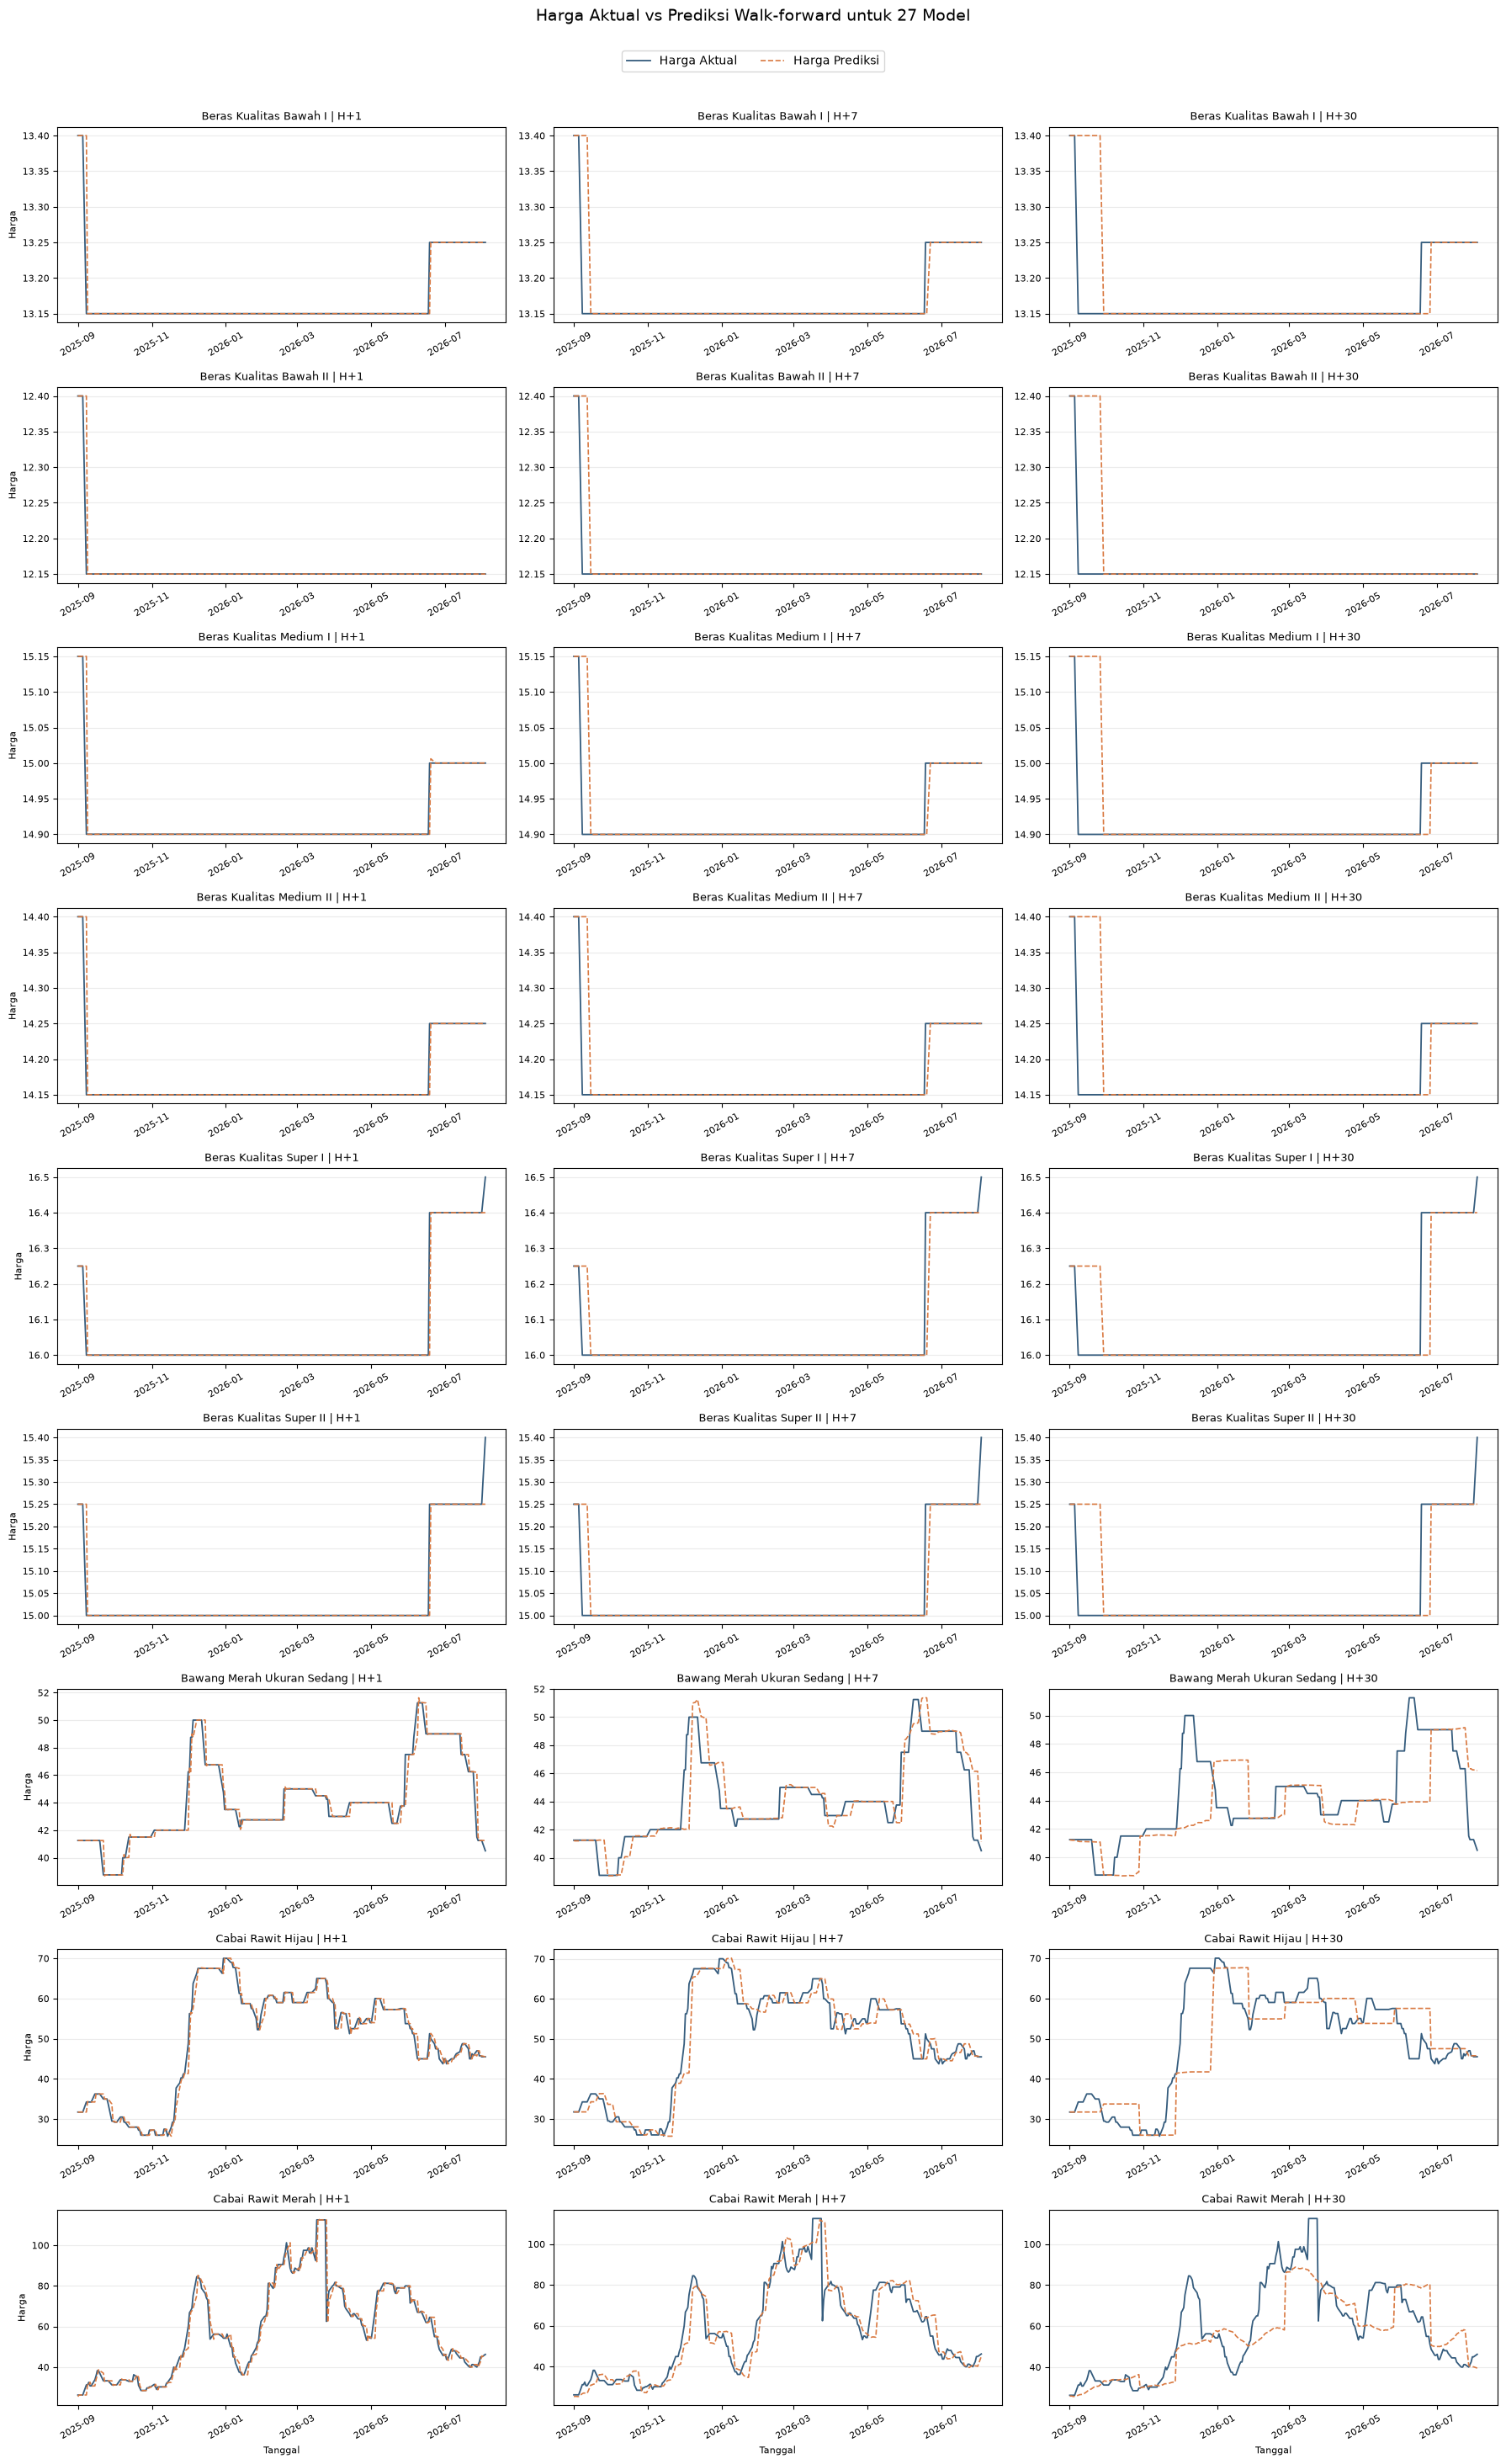

In [31]:
R.plot_walkforward(
    {"Harga Prediksi": (df_walkforward_predictions, "#d97941")},
    "Harga Aktual vs Prediksi Walk-forward untuk 27 Model",
    pred_linewidth=1.2,
)

## 33. Early Warning System H+30

Bandingkan prediksi H+30 dengan harga terakhir pada data train. Status: Waspada (> 5%), Warning (> 10%), dan Bahaya (> 20%).

In [32]:
h_ews = 30
df_ews = R.ews_table(forecasters_eval, h_ews=h_ews)
df_ews

,Komoditas,Tanggal origin,Harga origin (train),Prediksi H+30,Perubahan (%),Status
0,Beras Kualitas Bawah I,2025-08-29,13.4000,13.4000,-0.0000,Normal
1,Beras Kualitas Bawah II,2025-08-29,12.4000,12.4000,0.0000,Normal
2,Beras Kualitas Medium I,2025-08-29,15.1500,15.1500,0.0000,Normal
3,Beras Kualitas Medium II,2025-08-29,14.4000,14.4000,0.0000,Normal
4,Beras Kualitas Super I,2025-08-29,16.2500,16.2500,0.0000,Normal
5,Beras Kualitas Super II,2025-08-29,15.2500,15.2500,0.0000,Normal
6,Bawang Merah Ukuran Sedang,2025-08-29,41.2500,41.0820,-0.4073,Normal
7,Cabai Rawit Hijau,2025-08-29,31.7500,31.7645,0.0457,Normal
8,Cabai Rawit Merah,2025-08-29,25.5000,32.2507,26.4735,Bahaya


## 34. Menyimpan Final Model

Simpan forecaster GA untuk setiap komoditas dan horizon ke folder `final_model`.

In [33]:
R.save_forecasters(forecasters_ga, "final_model", "final_model_prediction")

tersimpan: Beras Kualitas Bawah I h=1
tersimpan: Beras Kualitas Bawah I h=7
tersimpan: Beras Kualitas Bawah I h=30
tersimpan: Beras Kualitas Bawah II h=1
tersimpan: Beras Kualitas Bawah II h=7
tersimpan: Beras Kualitas Bawah II h=30
tersimpan: Beras Kualitas Medium I h=1
tersimpan: Beras Kualitas Medium I h=7
tersimpan: Beras Kualitas Medium I h=30
tersimpan: Beras Kualitas Medium II h=1
tersimpan: Beras Kualitas Medium II h=7
tersimpan: Beras Kualitas Medium II h=30
tersimpan: Beras Kualitas Super I h=1
tersimpan: Beras Kualitas Super I h=7
tersimpan: Beras Kualitas Super I h=30
tersimpan: Beras Kualitas Super II h=1
tersimpan: Beras Kualitas Super II h=7
tersimpan: Beras Kualitas Super II h=30
tersimpan: Bawang Merah Ukuran Sedang h=1
tersimpan: Bawang Merah Ukuran Sedang h=7
tersimpan: Bawang Merah Ukuran Sedang h=30
tersimpan: Cabai Rawit Hijau h=1
tersimpan: Cabai Rawit Hijau h=7
tersimpan: Cabai Rawit Hijau h=30
tersimpan: Cabai Rawit Merah h=1
tersimpan: Cabai Rawit Merah h=7
te

## 35. Model Pembanding: XGBoost

Blok ini menambahkan XGBoost sebagai model pembanding LightGBM dengan pipeline yang sama (`log1p` → *differencing* orde 1 → `ForecasterDirect`). Pencarian hyperparameter memakai fungsi `running_for_ga` yang sama; hanya ruang gen dan *builder* parameternya yang diganti, sehingga protokol GA (fitness, jumlah generasi, seleksi) identik dan perbandingan kedua model tetap adil.

In [34]:
GENE_SPACE_XGB = [
    {"low": 3, "high": 6},  # max_depth
    {"low": 0.01, "high": 0.1},  # learning_rate
    {"low": 50, "high": 200},  # n_estimators
    {"low": 0.1, "high": 10.0},  # min_child_weight
    {"low": 0.6, "high": 0.9},  # subsample
    {"low": 0.6, "high": 0.9},  # colsample_bytree
    {"low": 0.6, "high": 1.0},  # colsample_bylevel
    {"low": 0.0, "high": 10.0},  # reg_alpha
    {"low": 0.0, "high": 10.0},  # reg_lambda
    {"low": 0.01, "high": 0.5},  # gamma (padanan min_split_gain)
]


def build_xgb_params(solution):
    return {
        "objective": "reg:absoluteerror",  # padanan regression_l1 pada LightGBM
        "max_depth": int(solution[0]),
        "learning_rate": solution[1],
        "n_estimators": int(solution[2]),
        "min_child_weight": solution[3],
        "subsample": solution[4],
        "colsample_bytree": solution[5],
        "colsample_bylevel": solution[6],
        "reg_alpha": solution[7],
        "reg_lambda": solution[8],
        "gamma": solution[9],
        "tree_method": "hist",
        "n_jobs": -1,
        "random_state": 42,
        "verbosity": 0,
    }


# sanity check: tiap gen terpakai dan estimator bisa dibentuk
_probe = build_xgb_params([gene["low"] for gene in GENE_SPACE_XGB])
assert _probe["max_depth"] == 3 and _probe["n_estimators"] == 50
assert _probe["gamma"] == 0.01 and isinstance(rc.make_xgb(_probe), xgb.XGBRegressor)
print(f"{len(GENE_SPACE_XGB)} gen XGBoost siap dioptimasi GA")

10 gen XGBoost siap dioptimasi GA


## 36. Melatih Baseline XGBoost (Parameter Default)

Pembanding awal: `ForecasterDirect` dengan parameter default XGBoost untuk setiap komoditas dan horizon, sebelum optimasi GA.

In [35]:
forecasters_default_xgb = R.fit_all_horizons(
    lambda: xgb.XGBRegressor(
        tree_method="hist", n_jobs=-1, random_state=42, verbosity=0
    )
)

## 37. Mencari Hyperparameter XGBoost dengan Genetic Algorithm

GA dijalankan ulang dengan `gene_space=GENE_SPACE_XGB` dan `build_params=build_xgb_params`. Fitness tetap negatif rata-rata MAE (skala log harga) pada empat fold validasi berurutan di dalam data train.

In [36]:
best_params_for_GA_xgb, forecasters_ga_xgb = run_ga_search(
    label="XGBoost",
    gene_space=GENE_SPACE_XGB,
    build_params=build_xgb_params,
    estimator_factory=rc.make_xgb,
)

[XGBoost] Beras Kualitas Bawah I: train 2021-01-04 → 2025-08-29 | test 2025-08-30 → 2026-08-03
Generation 1: Best MAE (skala log harga) = 0.000150
Generation 2: Best MAE (skala log harga) = 0.000150
Generation 3: Best MAE (skala log harga) = 0.000150
Generation 4: Best MAE (skala log harga) = 0.000150
Generation 5: Best MAE (skala log harga) = 0.000150
Generation 6: Best MAE (skala log harga) = 0.000150
Generation 7: Best MAE (skala log harga) = 0.000150
Generation 8: Best MAE (skala log harga) = 0.000150
Generation 1: Best MAE (skala log harga) = 0.000454
Generation 2: Best MAE (skala log harga) = 0.000454
Generation 3: Best MAE (skala log harga) = 0.000454
Generation 4: Best MAE (skala log harga) = 0.000454
Generation 5: Best MAE (skala log harga) = 0.000454
Generation 6: Best MAE (skala log harga) = 0.000454
Generation 7: Best MAE (skala log harga) = 0.000454
Generation 8: Best MAE (skala log harga) = 0.000454
Generation 1: Best MAE (skala log harga) = 0.000790
Generation 2: Best MA

## 38. Menampilkan Hyperparameter XGBoost Terbaik

Tampilkan parameter GA terpilih untuk setiap komoditas dan horizon.

In [37]:
rc.print_params_block(best_params_for_GA_xgb, horizons, suffix=" (XGBoost)")


Nama Komoditas: Beras Kualitas Bawah I (XGBoost)

Best parameters for horizon 1:
objective           : reg:absoluteerror
max_depth           : 5
learning_rate       : 0.039709
n_estimators        : 189
min_child_weight    : 8.323480
subsample           : 0.790021
colsample_bytree    : 0.871906
colsample_bylevel   : 0.709451
reg_alpha           : 1.865701
reg_lambda          : 8.925590
gamma               : 0.274278
tree_method         : hist
n_jobs              : -1
random_state        : 42
verbosity           : 0

Best parameters for horizon 7:
objective           : reg:absoluteerror
max_depth           : 5
learning_rate       : 0.039709
n_estimators        : 189
min_child_weight    : 8.323480
subsample           : 0.790021
colsample_bytree    : 0.871906
colsample_bylevel   : 0.709451
reg_alpha           : 1.865701
reg_lambda          : 8.925590
gamma               : 0.274278
tree_method         : hist
n_jobs              : -1
random_state        : 42
verbosity           : 0

Best pa

## 39. Menyimpan Hyperparameter dan Forecaster XGBoost

Simpan parameter terbaik ke `models/genetic_algorithm_parameters_xgboost.pkl` dan setiap forecaster GA ke folder `forecast_ga_xgb`. File inilah yang dipakai ulang oleh `code_run_training.ipynb` agar tidak perlu menjalankan GA lagi.

In [38]:
jl.dump(best_params_for_GA_xgb, "models/genetic_algorithm_parameters_xgboost.pkl")
R.save_forecasters(forecasters_ga_xgb, "forecast_ga_xgb", "forecasters_ga_xgb")

tersimpan: Beras Kualitas Bawah I h=1
tersimpan: Beras Kualitas Bawah I h=7
tersimpan: Beras Kualitas Bawah I h=30
tersimpan: Beras Kualitas Bawah II h=1
tersimpan: Beras Kualitas Bawah II h=7
tersimpan: Beras Kualitas Bawah II h=30
tersimpan: Beras Kualitas Medium I h=1
tersimpan: Beras Kualitas Medium I h=7
tersimpan: Beras Kualitas Medium I h=30
tersimpan: Beras Kualitas Medium II h=1
tersimpan: Beras Kualitas Medium II h=7
tersimpan: Beras Kualitas Medium II h=30
tersimpan: Beras Kualitas Super I h=1
tersimpan: Beras Kualitas Super I h=7
tersimpan: Beras Kualitas Super I h=30
tersimpan: Beras Kualitas Super II h=1
tersimpan: Beras Kualitas Super II h=7
tersimpan: Beras Kualitas Super II h=30
tersimpan: Bawang Merah Ukuran Sedang h=1
tersimpan: Bawang Merah Ukuran Sedang h=7
tersimpan: Bawang Merah Ukuran Sedang h=30
tersimpan: Cabai Rawit Hijau h=1
tersimpan: Cabai Rawit Hijau h=7
tersimpan: Cabai Rawit Hijau h=30
tersimpan: Cabai Rawit Merah h=1
tersimpan: Cabai Rawit Merah h=7
te

## 40. Evaluasi Data Test: LightGBM vs XGBoost

Latih ulang forecaster XGBoost dengan parameter GA, prediksi `h` hari pertama data test, lalu bandingkan MAE, RMSE, dan MAPE-nya dengan hasil LightGBM (`df_eval`).

In [39]:
forecasters_eval_xgb, df_eval_xgb = R.evaluate_on_test(
    best_params_for_GA_xgb, rc.make_xgb
)
df_eval_comparison = df_eval.merge(
    df_eval_xgb,
    on=["Komoditas", "Horizon"],
    suffixes=(" LightGBM", " XGBoost"),
)
df_eval_comparison["Model Terbaik (MAPE)"] = np.where(
    df_eval_comparison["MAPE (%) XGBoost"] < df_eval_comparison["MAPE (%) LightGBM"],
    "XGBoost",
    "LightGBM",
)
df_eval_comparison

,Komoditas,Horizon,MAE LightGBM,RMSE LightGBM,MAPE (%) LightGBM,MAE XGBoost,RMSE XGBoost,MAPE (%) XGBoost,Model Terbaik (MAPE)
0,Beras Kualitas Bawah I,1,0.0000,0.0000,0.0000,0.0001,0.0001,0.0005,LightGBM
1,Beras Kualitas Bawah I,7,0.0000,0.0000,0.0000,0.0002,0.0003,0.0018,LightGBM
2,Beras Kualitas Bawah I,30,0.1750,0.2092,1.3308,0.1760,0.2102,1.3382,LightGBM
3,Beras Kualitas Bawah II,1,0.0000,0.0000,0.0000,0.0000,0.0000,0.0004,LightGBM
4,Beras Kualitas Bawah II,7,0.0000,0.0000,0.0000,0.0002,0.0002,0.0015,LightGBM
5,Beras Kualitas Bawah II,30,0.1750,0.2092,1.4403,0.1758,0.2100,1.4465,LightGBM
6,Beras Kualitas Medium I,1,0.0000,0.0000,0.0000,0.0001,0.0001,0.0006,LightGBM
7,Beras Kualitas Medium I,7,0.0000,0.0000,0.0000,0.0004,0.0004,0.0023,LightGBM
8,Beras Kualitas Medium I,30,0.1750,0.2092,1.1745,0.1764,0.2107,1.1839,LightGBM
9,Beras Kualitas Medium II,1,0.0000,0.0000,0.0000,0.0001,0.0001,0.0006,LightGBM


## 41. Backtesting Walk-forward XGBoost

Prosedur sama dengan Bagian 31: `walk_forward_evaluation` dipakai ulang dengan *estimator factory* XGBoost (blok `h` hari berturut-turut, galat hanya dihitung pada tanggal dengan observasi asli). Hasil XGBoost lalu digabung dengan `df_walkforward` milik LightGBM.

In [40]:
df_walkforward_xgb, df_walkforward_predictions_xgb = R.walk_forward_evaluation(
    best_params_for_GA_xgb, rc.make_xgb
)
df_walkforward_comparison = df_walkforward.merge(
    df_walkforward_xgb,
    on=["Komoditas", "Horizon", "Jumlah Observasi"],
    suffixes=(" LightGBM", " XGBoost"),
)
df_walkforward_comparison["Model Terbaik (MAPE)"] = np.where(
    df_walkforward_comparison["MAPE (%) XGBoost"]
    < df_walkforward_comparison["MAPE (%) LightGBM"],
    "XGBoost",
    "LightGBM",
)
df_walkforward_comparison

,Komoditas,Horizon,Jumlah Observasi,MAE LightGBM,RMSE LightGBM,MAPE (%) LightGBM,MAE XGBoost,RMSE XGBoost,MAPE (%) XGBoost,Model Terbaik (MAPE)
0,Beras Kualitas Bawah I,1,241,0.0015,0.0173,0.0110,0.0015,0.0173,0.0114,LightGBM
1,Beras Kualitas Bawah I,7,241,0.0060,0.0371,0.0457,0.0062,0.0372,0.0474,LightGBM
2,Beras Kualitas Bawah I,30,241,0.0180,0.0643,0.1371,0.0187,0.0646,0.1422,LightGBM
3,Beras Kualitas Bawah II,1,241,0.0010,0.0161,0.0085,0.0011,0.0161,0.0088,LightGBM
4,Beras Kualitas Bawah II,7,241,0.0052,0.0360,0.0427,0.0054,0.0360,0.0441,LightGBM
5,Beras Kualitas Bawah II,30,241,0.0156,0.0624,0.1281,0.0161,0.0626,0.1326,LightGBM
6,Beras Kualitas Medium I,1,241,0.0015,0.0173,0.0100,0.0015,0.0173,0.0102,LightGBM
7,Beras Kualitas Medium I,7,241,0.0060,0.0371,0.0403,0.0063,0.0372,0.0425,LightGBM
8,Beras Kualitas Medium I,30,241,0.0180,0.0643,0.1210,0.0190,0.0647,0.1276,LightGBM
9,Beras Kualitas Medium II,1,241,0.0015,0.0173,0.0102,0.0015,0.0173,0.0107,LightGBM


## 42. Plot Perbandingan Walk-forward LightGBM vs XGBoost

Setiap panel menumpuk harga aktual, prediksi LightGBM, dan prediksi XGBoost untuk satu komoditas dan horizon (9 komoditas × 3 horizon).

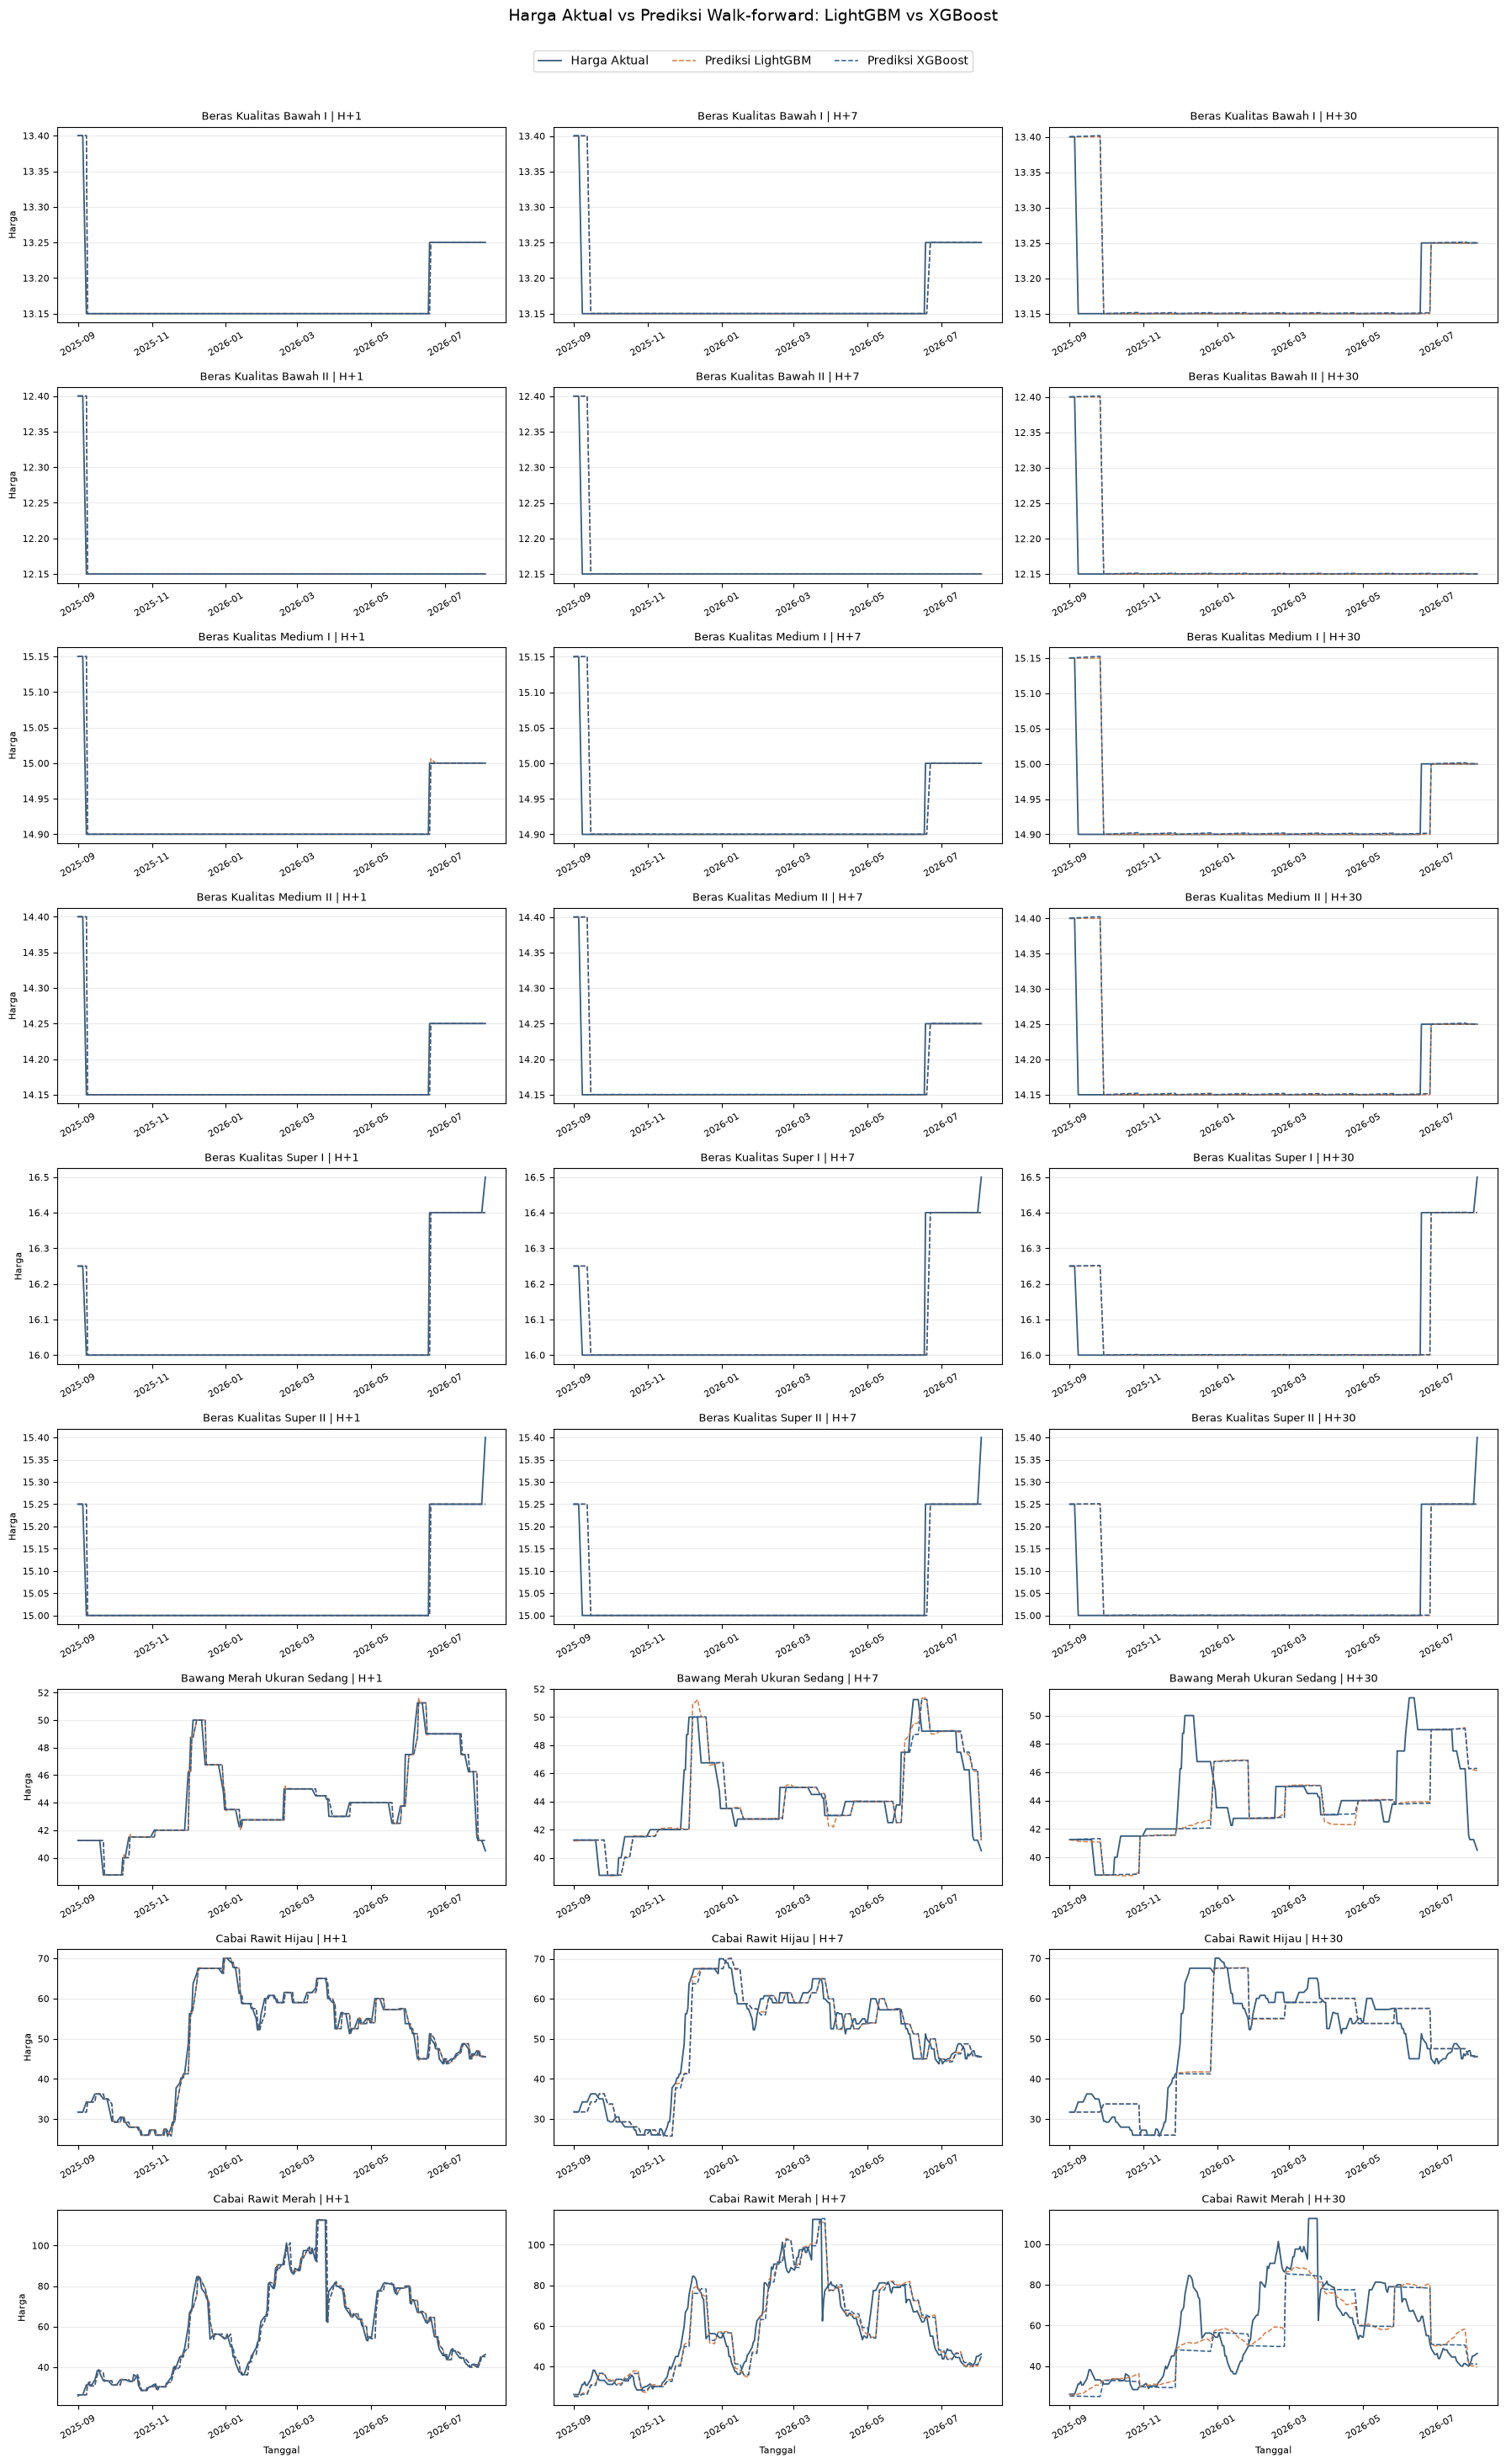

In [41]:
R.plot_walkforward(
    {
        "Prediksi LightGBM": (df_walkforward_predictions, "#d97941"),
        "Prediksi XGBoost": (df_walkforward_predictions_xgb, "#2b5c8f"),
    },
    "Harga Aktual vs Prediksi Walk-forward: LightGBM vs XGBoost",
)

## 43. Menyimpan Final Model XGBoost

Simpan forecaster XGBoost hasil GA ke folder `final_model_xgb`.

In [42]:
R.save_forecasters(forecasters_ga_xgb, "final_model_xgb", "final_model_prediction_xgb")

tersimpan: Beras Kualitas Bawah I h=1
tersimpan: Beras Kualitas Bawah I h=7
tersimpan: Beras Kualitas Bawah I h=30
tersimpan: Beras Kualitas Bawah II h=1
tersimpan: Beras Kualitas Bawah II h=7
tersimpan: Beras Kualitas Bawah II h=30
tersimpan: Beras Kualitas Medium I h=1
tersimpan: Beras Kualitas Medium I h=7
tersimpan: Beras Kualitas Medium I h=30
tersimpan: Beras Kualitas Medium II h=1
tersimpan: Beras Kualitas Medium II h=7
tersimpan: Beras Kualitas Medium II h=30
tersimpan: Beras Kualitas Super I h=1
tersimpan: Beras Kualitas Super I h=7
tersimpan: Beras Kualitas Super I h=30
tersimpan: Beras Kualitas Super II h=1
tersimpan: Beras Kualitas Super II h=7
tersimpan: Beras Kualitas Super II h=30
tersimpan: Bawang Merah Ukuran Sedang h=1
tersimpan: Bawang Merah Ukuran Sedang h=7
tersimpan: Bawang Merah Ukuran Sedang h=30
tersimpan: Cabai Rawit Hijau h=1
tersimpan: Cabai Rawit Hijau h=7
tersimpan: Cabai Rawit Hijau h=30
tersimpan: Cabai Rawit Merah h=1
tersimpan: Cabai Rawit Merah h=7
te